In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# load dataset
df = pd.read_csv('../data/adhdata.csv')
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns}')
print(f'Data lacks: {df.isnull().values.any()}')

Shape: (2166383, 21)
Columns: Index(['Fp1', 'Fp2', 'F3', 'F4', 'C3', 'C4', 'P3', 'P4', 'O1', 'O2', 'F7',
       'F8', 'T7', 'T8', 'P7', 'P8', 'Fz', 'Cz', 'Pz', 'Class', 'ID'],
      dtype='str')
Data lacks: False


In [7]:
# check dataset balance over adhd and control groups
patient_counts = df.groupby('Class')['ID'].nunique()
print(patient_counts)

Class
ADHD       61
Control    60
Name: ID, dtype: int64


Z literatury naukowej wynika, że kluczowymi wskaźnikami w ADHD są obszary czołowe (np. elektroda Fz) oraz pasma częstotliwości Theta i Beta (wskaźnik TBR). W związku z tym w analizie exploratorycznej przyjrzymy się bliżej rozkładom wartości w kanałach czołowych

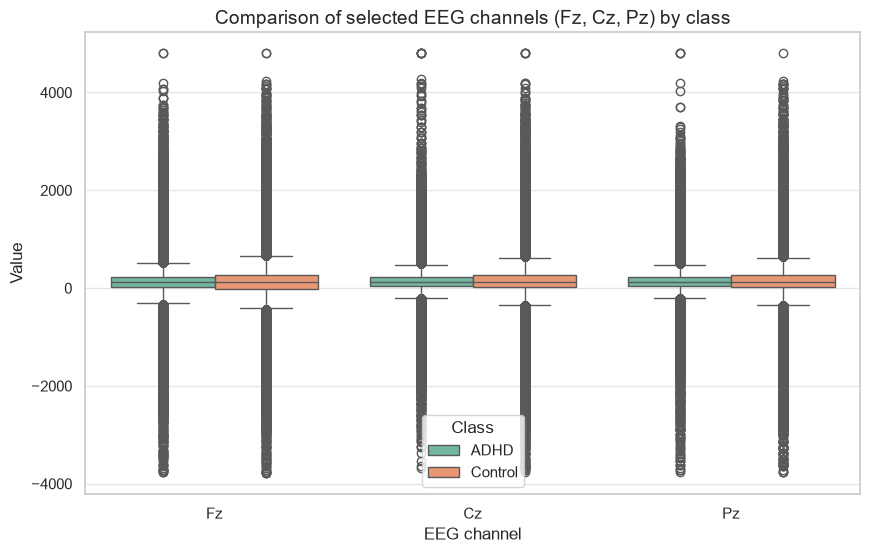

In [11]:
channels_to_plot = ['Fz', 'Cz', 'Pz']
df_melted = df.melt(id_vars=['ID', 'Class'], value_vars=channels_to_plot,
                    var_name='Channel', value_name='Value')

plt.figure(figsize=(10, 6))
sns.boxplot(x='Channel', y='Value', hue='Class', data=df_melted, palette='Set2')

plt.title('Comparison of selected EEG channels (Fz, Cz, Pz) by class', fontsize=14)
plt.xlabel('EEG channel', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.legend(title='Class')
plt.show()